## Knowledge Discovery and Interpretable Inference in Digital Twins via Rule Learning

This tutorial introduces neurosymbolic rule learning in digital twins for knowledge discovery and interpretable inference. 

Rule learning is the task of discovering patterns from data in the form of IF-THEN statements. In this tutorial, we will look into co-occurrence patterns.
For example, from the sensors of a water network we will learn rules such as:

&nbsp;&nbsp;&nbsp;&nbsp;**IF** `pipe_29_flow = high` **THEN** `leakage = yes` &nbsp;(true 100% of the time)

We propose a novel reframing of rule learning as a neurosymbolic problem, and this tutorial demonstrates it in a real-world use case of water distribution networks.

[![Scan the QR code or type tinyurl.com/4hu9t4rk to open this notebook in Google Colab](https://raw.githubusercontent.com/DiTEC-project/icsoc_tutorial/main/figures/access.png)](https://tinyurl.com/4hu9t4rk)

**Link:** https://tinyurl.com/4hu9t4rk

### Table of Contents

1. What data do we have?
2. What is the task of rule learning and why should you care?
3. How to learn only a small set of interesting rules with Aerial+ and PyAerial?
4. How to further evaluate whether the rules are good?
5. Can I use my own model instead of Autoencoders?
6. What else can we do?

## Before we start
Run the two cells below once (about 1 minute).

In [1]:
%pip install -q pyaerial xgboost pandas matplotlib scikit-learn


[notice] A new release of pip is available: 24.3.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
import os, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/tutorial"):
        !git clone -q https://github.com/DiTEC-project/icsoc_tutorial /content/tutorial
    %cd /content/tutorial
if not os.path.exists("tabprobe"):
    !git clone -q https://github.com/DiTEC-project/tabprobe.git
sys.path += ["src", "tabprobe"]

import logging, random, warnings
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
import preprocess, tutorial_utils as tu

warnings.filterwarnings("ignore")
logging.disable(logging.INFO)
tu.set_style()

def seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

## Part 1 · What data do we have?
One year of sensor readings from a water network with two leakages.

**Where are the sensors and the leaks?**
LeakDB [1] simulates leaks in the Hanoi water network. We use the 18 sensors that are at most 2 pipes away from a leak itself.

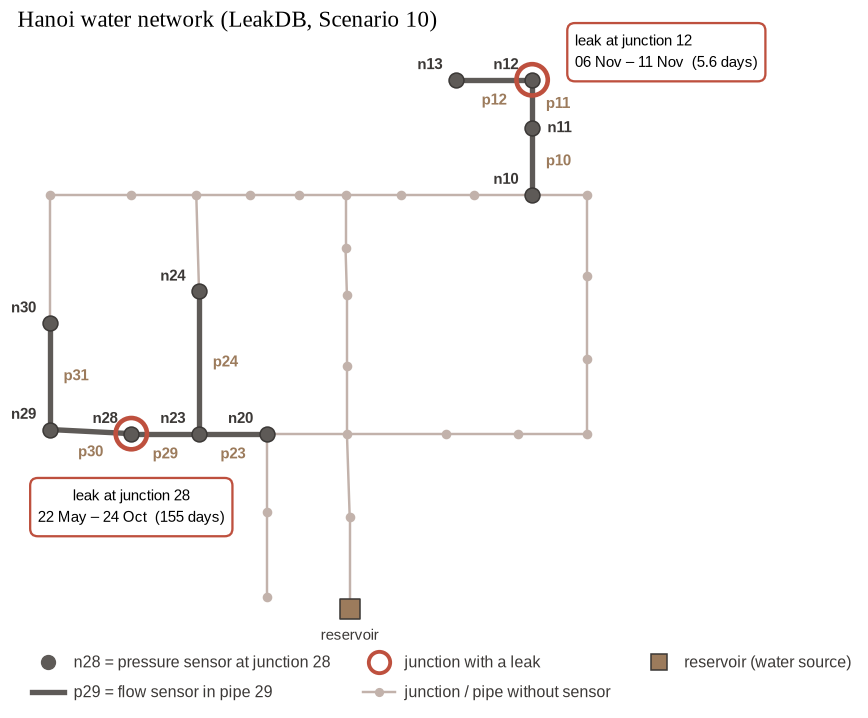

In [4]:
scenario = preprocess.download("Scenario-10")
table = preprocess.build_table(scenario, window="6h", hops=2)
sensors = [c for c in table.columns if c not in ("timestamp", "leakage")]

tu.draw_network(scenario, sensors)

**How to represent the data?**
We represent the sensor data as a table, where the columns are the sensors and the rows are the measurements per timeframe. In this tutorial, we used 6 hours of timeframes and aggregated the data with an average function.

Leakages are added as a separate column. If it has a value of 1, that means there is a leakage in the system. 

Below: the pressure at leak node 28 and the flow in pipe 29, which feeds that node.

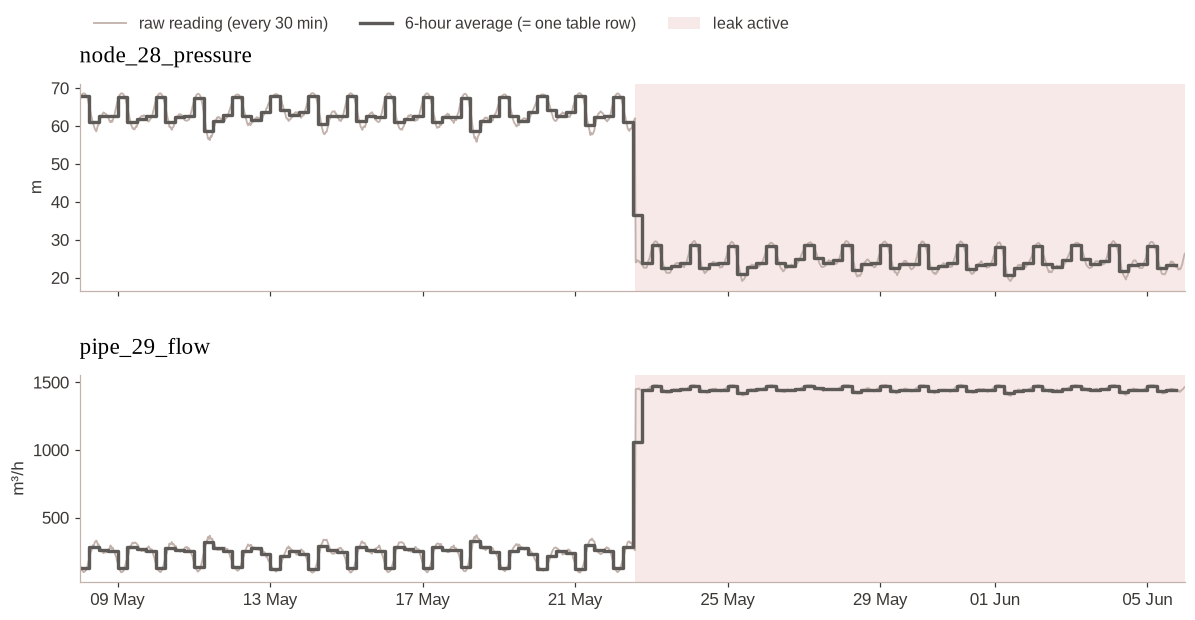

In [5]:
raw = preprocess.read_sensors(scenario)
tu.plot_aggregation(raw, table, ["node_28_pressure", "pipe_29_flow"], scenario)

In [6]:
cols = ["timestamp", "node_28_pressure", "pipe_29_flow", "node_12_pressure", "leakage"]
tu.show(table.loc[562:567, cols].round(1))   # 4 of the 18 sensors, as the leak at node 28 starts

#,timestamp,node_28_pressure,pipe_29_flow,node_12_pressure,leakage
563,21 May 12:00,62.5,258.0,63.5,0
564,21 May 18:00,62.7,253.2,63.7,0
565,22 May 00:00,67.8,129.0,68.0,0
566,22 May 06:00,61.0,283.8,62.3,0
567,22 May 12:00,36.5,1059.6,62.2,1
568,22 May 18:00,23.8,1446.9,61.5,1


**Why low / mid / high?**
Rules speak in categories, not numbers, so each reading becomes low, mid or high.

In [7]:
data = tu.discretize(table)
tu.show(data.loc[562:567, cols[1:]])

#,node_28_pressure,pipe_29_flow,node_12_pressure,leakage
563,high,low,high,no
564,high,low,high,no
565,high,low,high,no
566,high,low,high,no
567,mid,high,high,yes
568,low,high,high,yes


## Part 2 · What is the task of rule learning and why should you care?

**What is a rule?**

&nbsp;&nbsp;&nbsp;&nbsp;**IF** `pipe_29_flow = high` **THEN** `leakage = yes`

- **support**: how often IF and THEN are true *together*
- **confidence**: how often THEN is true, *when IF is true*

**How many rules could there be?** Even for our small table:

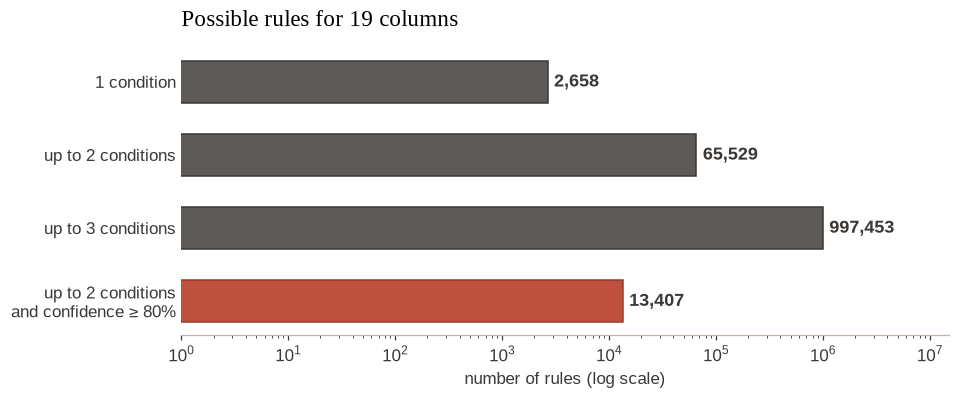

In [8]:
possible = tu.count_possible_rules(data, max_len=3)
all_rules = tu.mine_all_rules(data, max_len=2)          # classical exhaustive search
strong = all_rules[all_rules.confidence >= 0.8]

tu.plot_rule_explosion(possible, len(strong))

**Is a rule with high confidence always useful?**
No. E.g., we also have to compare it with the **base rate**: how often THEN is true *anyway*.

In [9]:
tu.explain_examples(data, [
    ({"pipe_11_flow": "low"},        ("node_12_pressure", "high"), "mostly high anyway"),
    ({"node_12_pressure": "high"},   ("pipe_10_flow", "low"),      "almost always low anyway"),
    ({"pipe_29_flow": "high"},       ("leakage", "yes"),           "confidence far above base rate"),
    ({"pipe_10_flow": "low", "pipe_29_flow": "high"}, ("leakage", "yes"), "repeats the rule above"),
], highlight=3)

#,Rule,Support,Confidence,Base rate,Why
1,pipe_11_flow = low → node_12_pressure = high,86%,88%,86%,mostly high anyway
2,node_12_pressure = high → pipe_10_flow = low,86%,100%,98%,almost always low anyway
3,pipe_29_flow = high → leakage = yes,42%,100%,44%,confidence far above base rate
4,pipe_10_flow = low AND pipe_29_flow = high → leakage = yes,42%,100%,44%,repeats the rule above


So we want **a few rules that tell us something new**, without listing millions of them.

## Part 3 · How to learn only a small set of interesting rules with Aerial+ and PyAerial?
A neural network learns the patterns in the table, and then we probe it with queries [2, 3].

![How Aerial+ works](https://raw.githubusercontent.com/DiTEC-project/icsoc_tutorial/main/figures/aerial.png)

**Let's try it:** learn rules that say something about `leakage`.

In [10]:
from aerial import model, rule_extraction

seed(0)
autoencoder = model.train(data, layer_dims=[16], epochs=2, show_progress=False)
rules = rule_extraction.generate_rules(autoencoder, target_classes=["leakage"])["rules"]

print(len(rules), "rules")
tu.rules_table(rules, n=20)

88 rules


#,IF,THEN,support,confidence
1,pipe_23_flow = low,leakage = no,46%,97%
2,pipe_29_flow = high,leakage = yes,42%,100%
3,node_28_pressure = low,leakage = yes,42%,100%
4,node_29_pressure = low,leakage = yes,42%,100%
5,pipe_30_flow = low,leakage = yes,42%,100%
6,pipe_31_flow = low,leakage = yes,42%,100%
7,pipe_23_flow = high,leakage = yes,32%,100%
8,node_28_pressure = high AND pipe_31_flow = high,leakage = no,56%,97%
9,node_28_pressure = high AND pipe_30_flow = high,leakage = no,56%,97%
10,node_28_pressure = high AND node_29_pressure = high,leakage = no,56%,97%


**What do support and confidence look like?**
Each lane shows when that side of the rule is true. Try another rule by changing `row`.

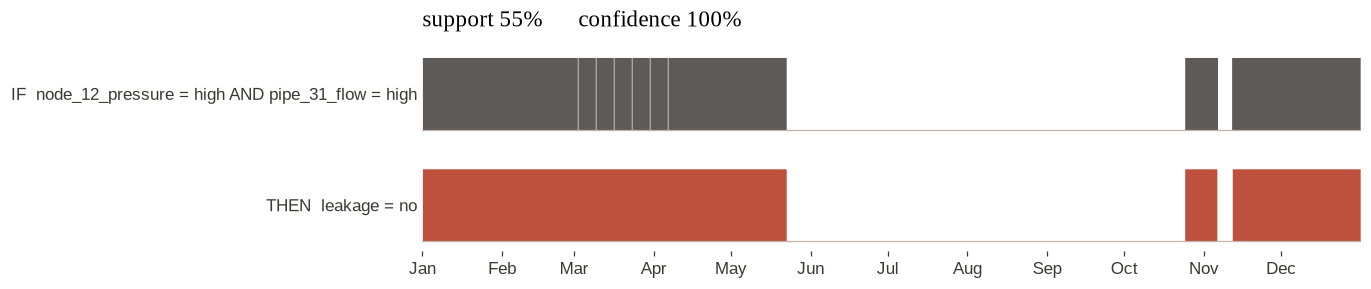

In [12]:
row = 18   # any row number (#) from the table above
tu.plot_rule_timeline(data, table.timestamp, tu.rule_at(rules, row))

**Which rules describe the leaks?**
We ask only for rules that end in `leakage = yes`.

In [13]:
leak_rules = rule_extraction.generate_rules(autoencoder, target_classes=[{"leakage": "yes"}])["rules"]

print(len(leak_rules), "leakage rules")
tu.rules_table(leak_rules, n=10)

30 leakage rules


#,IF,THEN,support,confidence
1,pipe_29_flow = high,leakage = yes,42%,100%
2,node_28_pressure = low,leakage = yes,42%,100%
3,node_29_pressure = low,leakage = yes,42%,100%
4,pipe_30_flow = low,leakage = yes,42%,100%
5,pipe_31_flow = low,leakage = yes,42%,100%
6,pipe_23_flow = high,leakage = yes,32%,100%
7,pipe_11_flow = low AND pipe_29_flow = high,leakage = yes,42%,100%
8,pipe_10_flow = low AND pipe_29_flow = high,leakage = yes,42%,100%
9,node_28_pressure = low AND pipe_11_flow = low,leakage = yes,42%,100%
10,pipe_11_flow = low AND pipe_31_flow = low,leakage = yes,42%,100%


**Do they make sense?**
They point to the sensors around the leaks, so we can check every rule on the map.

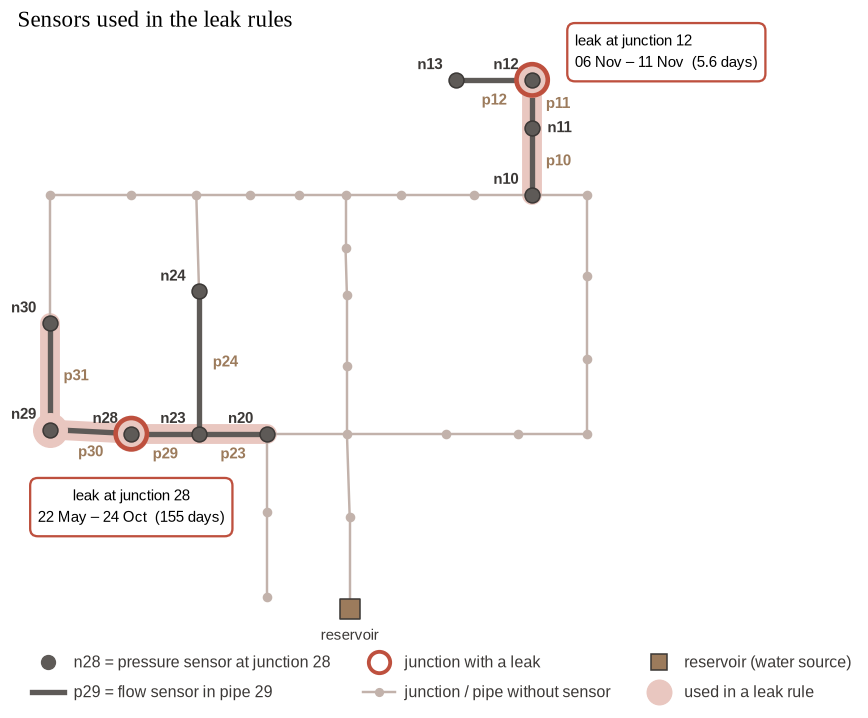

In [14]:
tu.draw_network(scenario, sensors, highlight=tu.rule_sensors(leak_rules), title_text="Sensors used in the leak rules")

**Can I control how many rules I get?**
Yes. The autoencoder squeezes each row through a **bottleneck**: the smaller it is, the fewer patterns survive.

Other settings: `min_rule_frequency` (≈ support), `min_rule_strength` (≈ confidence), `max_antecedents` (rule length).

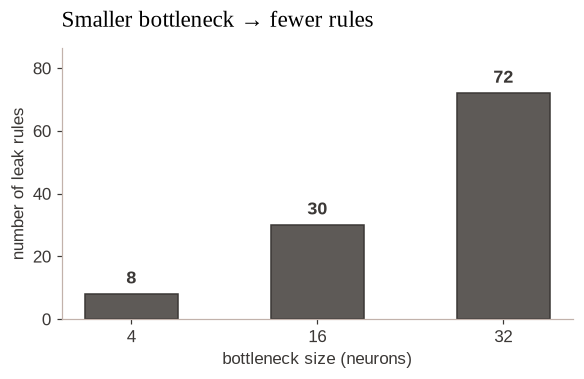

In [15]:
by_size = {}
for size in [4, 16, 32]:
    seed(0)
    ae = model.train(data, layer_dims=[size], epochs=2, show_progress=False)
    by_size[size] = rule_extraction.generate_rules(ae, target_classes=[{"leakage": "yes"}])["rules"]

tu.plot_bottleneck(by_size)

In [16]:
tu.rules_table(by_size[4])

#,IF,THEN,support,confidence
1,node_29_pressure = low AND pipe_30_flow = low,leakage = yes,42%,100%
2,pipe_30_flow = low AND pipe_31_flow = low,leakage = yes,42%,100%
3,pipe_29_flow = high AND pipe_30_flow = low,leakage = yes,42%,100%
4,node_28_pressure = low AND node_29_pressure = low,leakage = yes,42%,100%
5,node_29_pressure = low AND pipe_31_flow = low,leakage = yes,42%,100%
6,node_29_pressure = low AND pipe_29_flow = high,leakage = yes,42%,100%
7,node_28_pressure = low AND pipe_31_flow = low,leakage = yes,42%,100%
8,node_28_pressure = low AND pipe_29_flow = high,leakage = yes,42%,100%


## Part 4 · How to further evaluate whether the rules are good?
We learn rules on part of the year and check them on weeks the model has never seen.

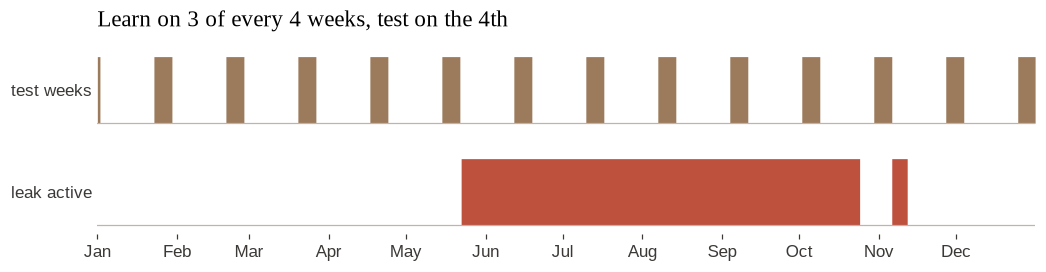

In [17]:
week = table.timestamp.dt.isocalendar().week.values
test = week % 4 == 0
tu.plot_split(table.timestamp, test, table)

**Are the rules still confident on unseen weeks?**
Each dot is one rule learned on the training weeks.

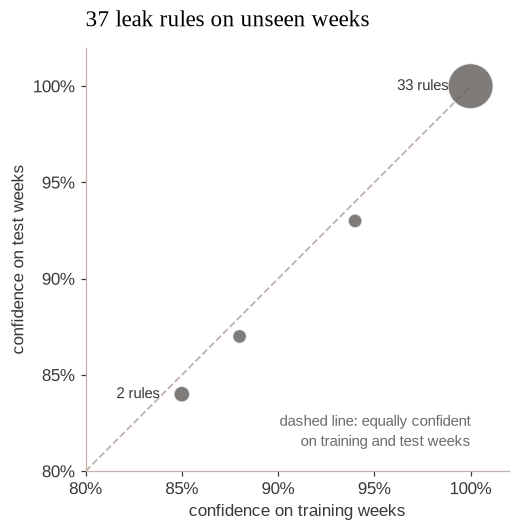

In [18]:
seed(0)
ae = model.train(data[~test], layer_dims=[16], epochs=2, show_progress=False)
train_rules = rule_extraction.generate_rules(ae, target_classes=[{"leakage": "yes"}])["rules"]

tu.plot_train_vs_test(train_rules, data[test])

**Can the rules detect leaks?**
Raise an alarm whenever a rule fires. Every alarm comes with its reason: the rule itself.

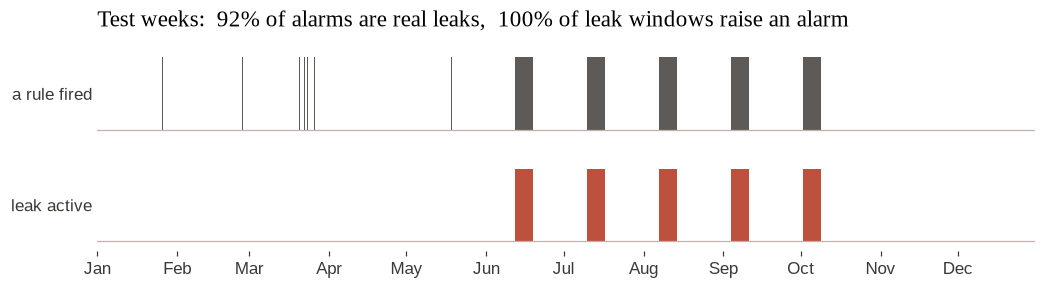

In [19]:
alarm = np.any([tu.fires(r["antecedents"], data[test]) for r in train_rules], axis=0)
tu.plot_alarms(table.timestamp[test], data[test], alarm)

## Part 5 · Can I use my own model instead of Autoencoders?
Yes. TabProbe turns any model that predicts a column from the other columns into a rule learner [6].

![How TabProbe works](https://raw.githubusercontent.com/DiTEC-project/icsoc_tutorial/main/figures/tabprobe.png)

Same two steps as Aerial+, only the model changes: tabular foundation models (TabPFN, TabICL, TabDPT), XGBoost, random forests, …

**Let's try it with XGBoost [9]:**

In [20]:
from src.wrapper import TabProbe

miner = TabProbe(method="xgboost", max_antecedents=2, ant_similarity=0.5, cons_similarity=0.8)
xgb_rules = miner.mine_rules(data, metrics=["support", "confidence"])
xgb_leak_rules = [r for r in xgb_rules if r["consequent"] == {"feature": "leakage", "value": "yes"}]

print(len(xgb_rules), "rules,", len(xgb_leak_rules), "about leakage")

    Reconstructing 19 features for 53 queries (workers=1, batch_size=512, device=cpu, calibrate=False, calibration_method=sigmoid)...
    Reconstructing 19 features for 78 queries (workers=1, batch_size=512, device=cpu, calibrate=False, calibration_method=sigmoid)...
828 rules, 74 about leakage


**Can we trust every rule?**
XGBoost is often over-confident, so we keep only the rules that also hold on the data.

In [21]:
xgb_leak_rules = [r for r in xgb_leak_rules if r["confidence"] >= 0.8]
tu.rules_table(xgb_leak_rules, n=10)

#,IF,THEN,support,confidence
1,pipe_29_flow = high,leakage = yes,42%,100%
2,node_10_pressure = mid,leakage = yes,26%,88%
3,node_23_pressure = mid,leakage = yes,20%,85%
4,pipe_10_flow = low AND pipe_29_flow = high,leakage = yes,42%,100%
5,pipe_11_flow = low AND pipe_29_flow = high,leakage = yes,42%,100%
6,node_12_pressure = high AND pipe_29_flow = high,leakage = yes,31%,100%
7,node_13_pressure = high AND pipe_29_flow = high,leakage = yes,28%,100%
8,node_10_pressure = mid AND pipe_29_flow = high,leakage = yes,26%,100%
9,node_10_pressure = mid AND pipe_10_flow = low,leakage = yes,26%,87%
10,node_10_pressure = mid AND pipe_11_flow = low,leakage = yes,26%,87%


**Do both methods find the same leaks?**

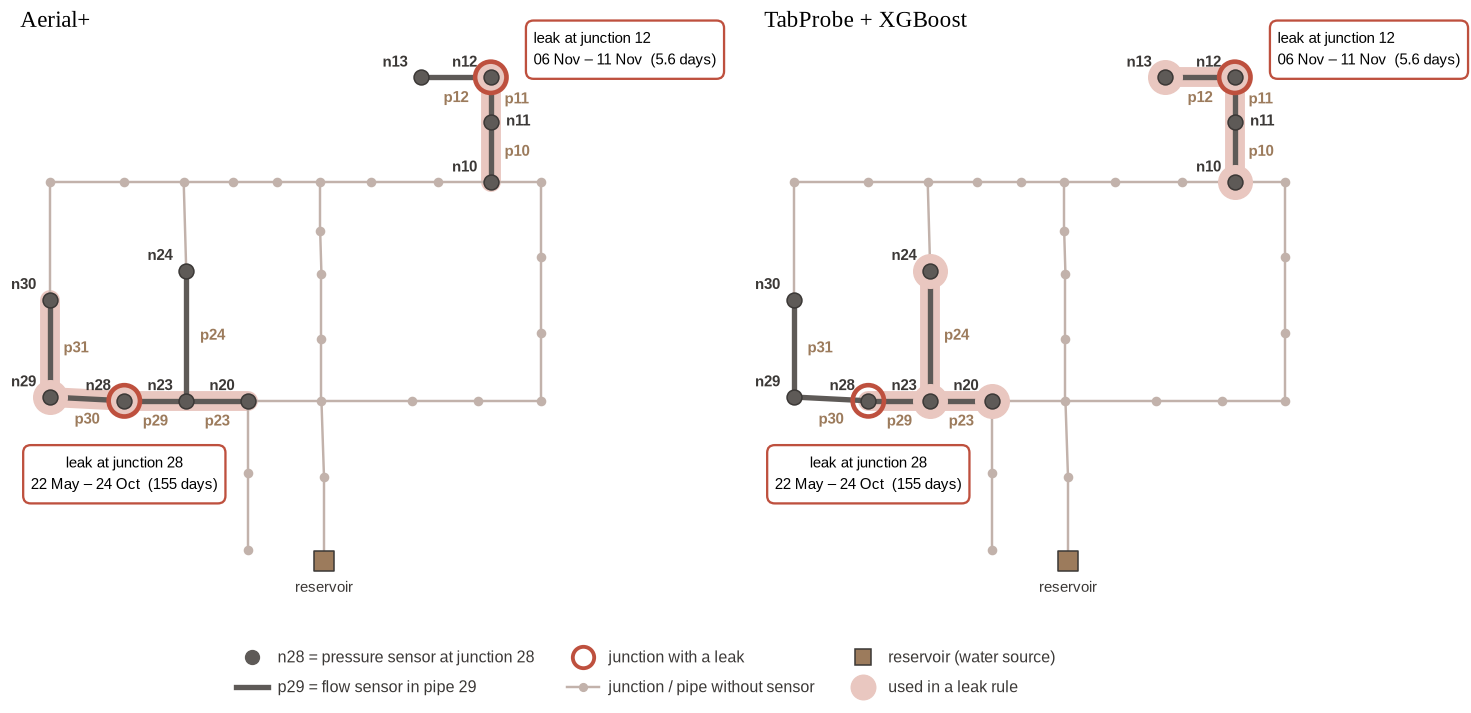

In [22]:
tu.compare_networks(scenario, sensors, {"Aerial+": leak_rules, "TabProbe + XGBoost": xgb_leak_rules})

**Your turn:** change `method="xgboost"` to `"random_forest"`.
With a GPU runtime, try `"tabpfn"` or `"tabicl"` (`pip install tabpfn` / `tabicl`).

## Part 6 · What else can we do?
Three more questions we answered in recent papers.

- **What if I don't want to choose low / mid / high myself?**
  DiffNARM learns the ranges together with the rules [7].
- **What if I have very few rows but thousands of columns**?
  Transfer learning from a tabular foundation model into Aerial+ [5], or use TabProbe [6] directly on a tabular foundation model, i.e., TabPFN [8].
- **Can rules know the network itself?**
  With a **knowledge graph** of the network, rules can say *"IF a flow sensor in a pipe longer than L reads V1, THEN the pressure sensor at the connected junction reads V2"* [4].

**Code:** [PyAerial](https://github.com/DiTEC-project/pyaerial) · [TabProbe](https://github.com/DiTEC-project/tabprobe) · [DiffNARM](https://github.com/DiTEC-project/diffnarm)

## References

1. Vrachimis, Stelios G., and Marios S. Kyriakou. "Leakdb: a benchmark dataset for leakage diagnosis in water distribution networks:(146)." WDSA/CCWI joint conference proceedings. Vol. 1. 2018.
2. Karabulut, Erkan, Paul Groth, and Victoria Degeler. “Neurosymbolic Association Rule Mining from Tabular Data.” Proceedings of the 19th International Conference on Neurosymbolic Learning and Reasoning (NeSy). Proceedings of Machine Learning Research 284, PMLR, 2025, pp. 565–88, https://proceedings.mlr.press/v284/karabulut25a.html.
3. Karabulut, Erkan, Paul Groth, and Victoria Degeler. “PyAerial: Scalable association rule mining from tabular data.” SoftwareX, vol. 31, 2025, p. 102341. https://doi.org/10.1016/j.softx.2025.102341.
4. Karabulut, Erkan, Paul Groth, and Victoria Degeler. “Learning semantic association rules from internet of things data.” Neurosymbolic Artificial Intelligence, vol. 1, 2025. https://doi.org/10.1177/29498732251377518.
5. Karabulut, Erkan, Daniel Daza, Paul Groth, and Victoria Degeler. “Discovering Association Rules in High-Dimensional Small Tabular Data.” 1st International Workshop on Advanced NeuroSymbolic Applications (ANSyA), at ECAI 2025. CEUR Workshop Proceedings 4125, CEUR-WS,
2025, pp. 105–13, ceur-ws.org/Vol-4125/paper_26.pdf.
6. Karabulut, Erkan, Daniel Daza, Paul Groth, M.C. Schut, and Victoria Degeler. “Model-Agnostic Association Rule Learning with Tabular Foundation Models.” Transactions on Machine Learning Research, 2026. https://penreview.net/forum?id=Y70lnNnA6T.
7. Karabulut, Erkan, Daniel Daza, Emile van Krieken, Paul Groth, and Victoria Degeler. “Differentiable Numerical Association Rule Learning.” Transactions on Machine Learning Research, 2026. https://openreview.net/forum?id=0WZf2uidpa.
8. Hollmann, Noah, et al. "Accurate predictions on small data with a tabular foundation model." Nature 637.8045 (2025): 319-326.
9. Chen, Tianqi, and Carlos Guestrin. "Xgboost: A scalable tree boosting system." Proceedings of the 22nd acm sigkdd international conference on knowledge discovery and data mining. 2016.